In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, recall_score, precision_score, roc_curve, auc, roc_auc_score


In [2]:
import pandas as pd

from pathlib import Path

notebook_dir = Path.cwd()
dataset_path = notebook_dir / "Telecom-Customer-Churn_Dataset.csv"
if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset was not found: {dataset_path}")

data = pd.read_csv(dataset_path)
print(data.shape)


(1000018, 21)


In [3]:
data.head()

,CustomerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CID0000001,Female,1,No,No,31,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,73.90,2217.15,Yes
1,CID0000002,Male,1,Yes,No,3,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,105.90,334.65,Yes
2,CID0000003,Male,0,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,74.90,74.90,Yes
3,CID0000004,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No
4,CID0000005,Female,0,No,Yes,65,No,No phone service,DSL,No,...,No,Yes,Yes,No,Two year,No,Mailed check,45.25,2933.95,No


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000018 entries, 0 to 1000017
Data columns (total 21 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   CustomerID        1000018 non-null  str    
 1   gender            1000018 non-null  str    
 2   SeniorCitizen     1000018 non-null  int64  
 3   Partner           1000018 non-null  str    
 4   Dependents        1000018 non-null  str    
 5   tenure            1000018 non-null  int64  
 6   PhoneService      1000018 non-null  str    
 7   MultipleLines     1000018 non-null  str    
 8   InternetService   1000018 non-null  str    
 9   OnlineSecurity    1000018 non-null  str    
 10  OnlineBackup      1000018 non-null  str    
 11  DeviceProtection  1000018 non-null  str    
 12  TechSupport       1000018 non-null  str    
 13  StreamingTV       1000018 non-null  str    
 14  StreamingMovies   1000018 non-null  str    
 15  Contract          1000018 non-null  str    
 16  PaperlessBi

In [5]:
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
original_rows = len(data)
data = data.dropna(subset=['TotalCharges'])
print(f"Total dropped rows with NaNs: {original_rows - len(data)}")

Total dropped rows with NaNs: 0


In [6]:
data.columns

Index(['CustomerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
target_feature = 'Churn'
numeric_features = ['MonthlyCharges', 'TotalCharges', 'tenure']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
      'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']

In [8]:
X = data[numeric_features + categorical_features]
y = data[target_feature]

In [9]:
from collections import Counter
Counter(y)
#The data is imbalanced since yes and no are not 50-50

Counter({'No': 734644, 'Yes': 265374})

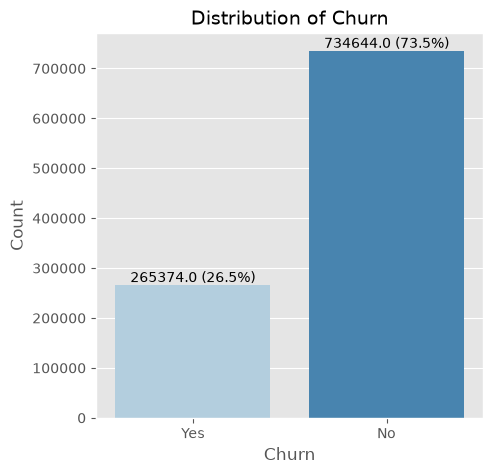

In [10]:
plt.style.use("ggplot")


plt.figure(figsize=(5, 5))

total = len(data)


ax = sns.countplot(data=data, x="Churn", hue="Churn", palette="Blues", legend=False)


for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{v.get_height()} ({v.get_height() / total:.1%})" for v in container],
        label_type="edge",
        fontsize=10
    )


plt.title("Distribution of Churn", fontsize=14)
plt.xlabel("Churn")
plt.ylabel("Count")

plt.show()

,count,mean,std,min,25%,50%,75%,max
MonthlyCharges,1000018.0,64.77,30.08,18.25,35.55,70.35,89.85,118.75
TotalCharges,1000018.0,2278.39,2267.12,0.00,396.30,1394.55,3778.00,8684.80
tenure,1000018.0,32.34,24.56,0.00,9.00,29.00,55.00,72.00


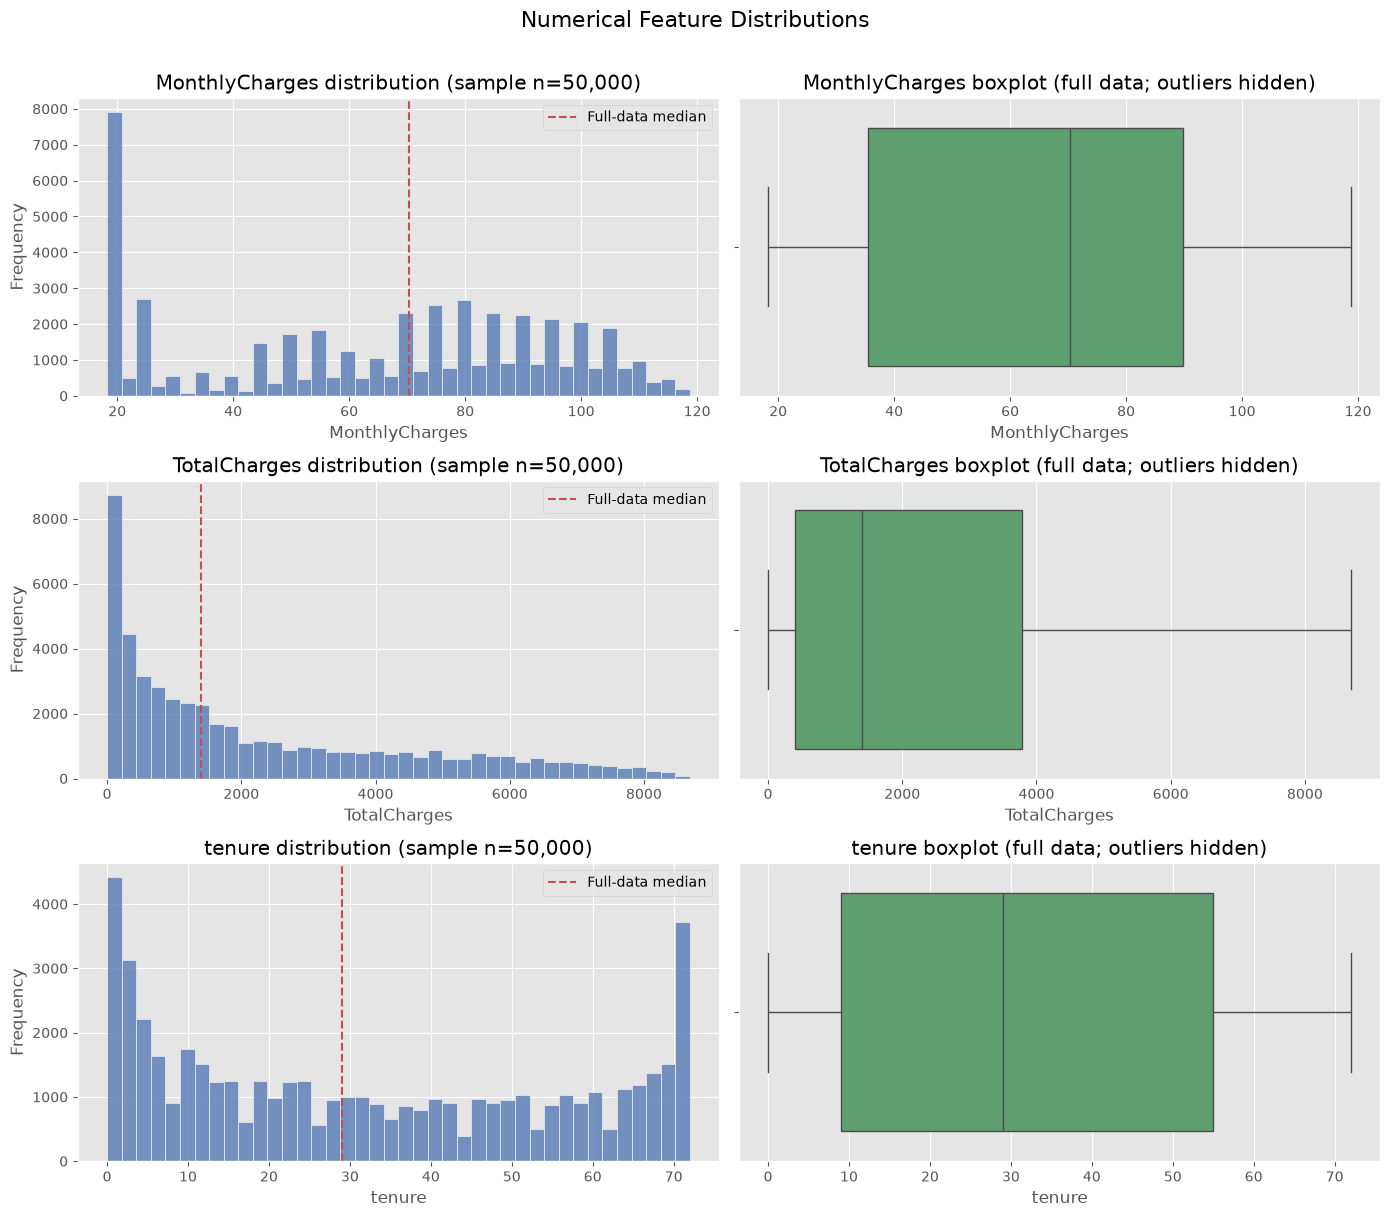

In [11]:
numeric_columns = ["MonthlyCharges", "TotalCharges", "tenure"]
numeric_data = data[numeric_columns].apply(pd.to_numeric, errors="coerce")
display(numeric_data.describe().T.round(2))

sample_size = min(50_000, len(numeric_data))
plot_sample = numeric_data.sample(n=sample_size, random_state=42)
fig, axes = plt.subplots(
    nrows=len(numeric_columns),
    ncols=2,
    figsize=(14, 4 * len(numeric_columns)),
)

for row, column in enumerate(numeric_columns):
    hist_ax, box_ax = axes[row]
    sns.histplot(
        plot_sample[column].dropna(),
        bins=40,
        color="#4C72B0",
        ax=hist_ax,
    )
    hist_ax.axvline(
        numeric_data[column].median(),
        color="#C44E52",
        linestyle="--",
        label="Full-data median",
    )
    hist_ax.set_title(f"{column} distribution (sample n={sample_size:,})")
    hist_ax.set_xlabel(column)
    hist_ax.set_ylabel("Frequency")
    hist_ax.legend()

    sns.boxplot(
        x=numeric_data[column],
        color="#55A868",
        showfliers=False,
        ax=box_ax,
    )
    box_ax.set_title(f"{column} boxplot (full data; outliers hidden)")
    box_ax.set_xlabel(column)

fig.suptitle("Numerical Feature Distributions", fontsize=16, y=1.01)
fig.tight_layout()
plt.show()

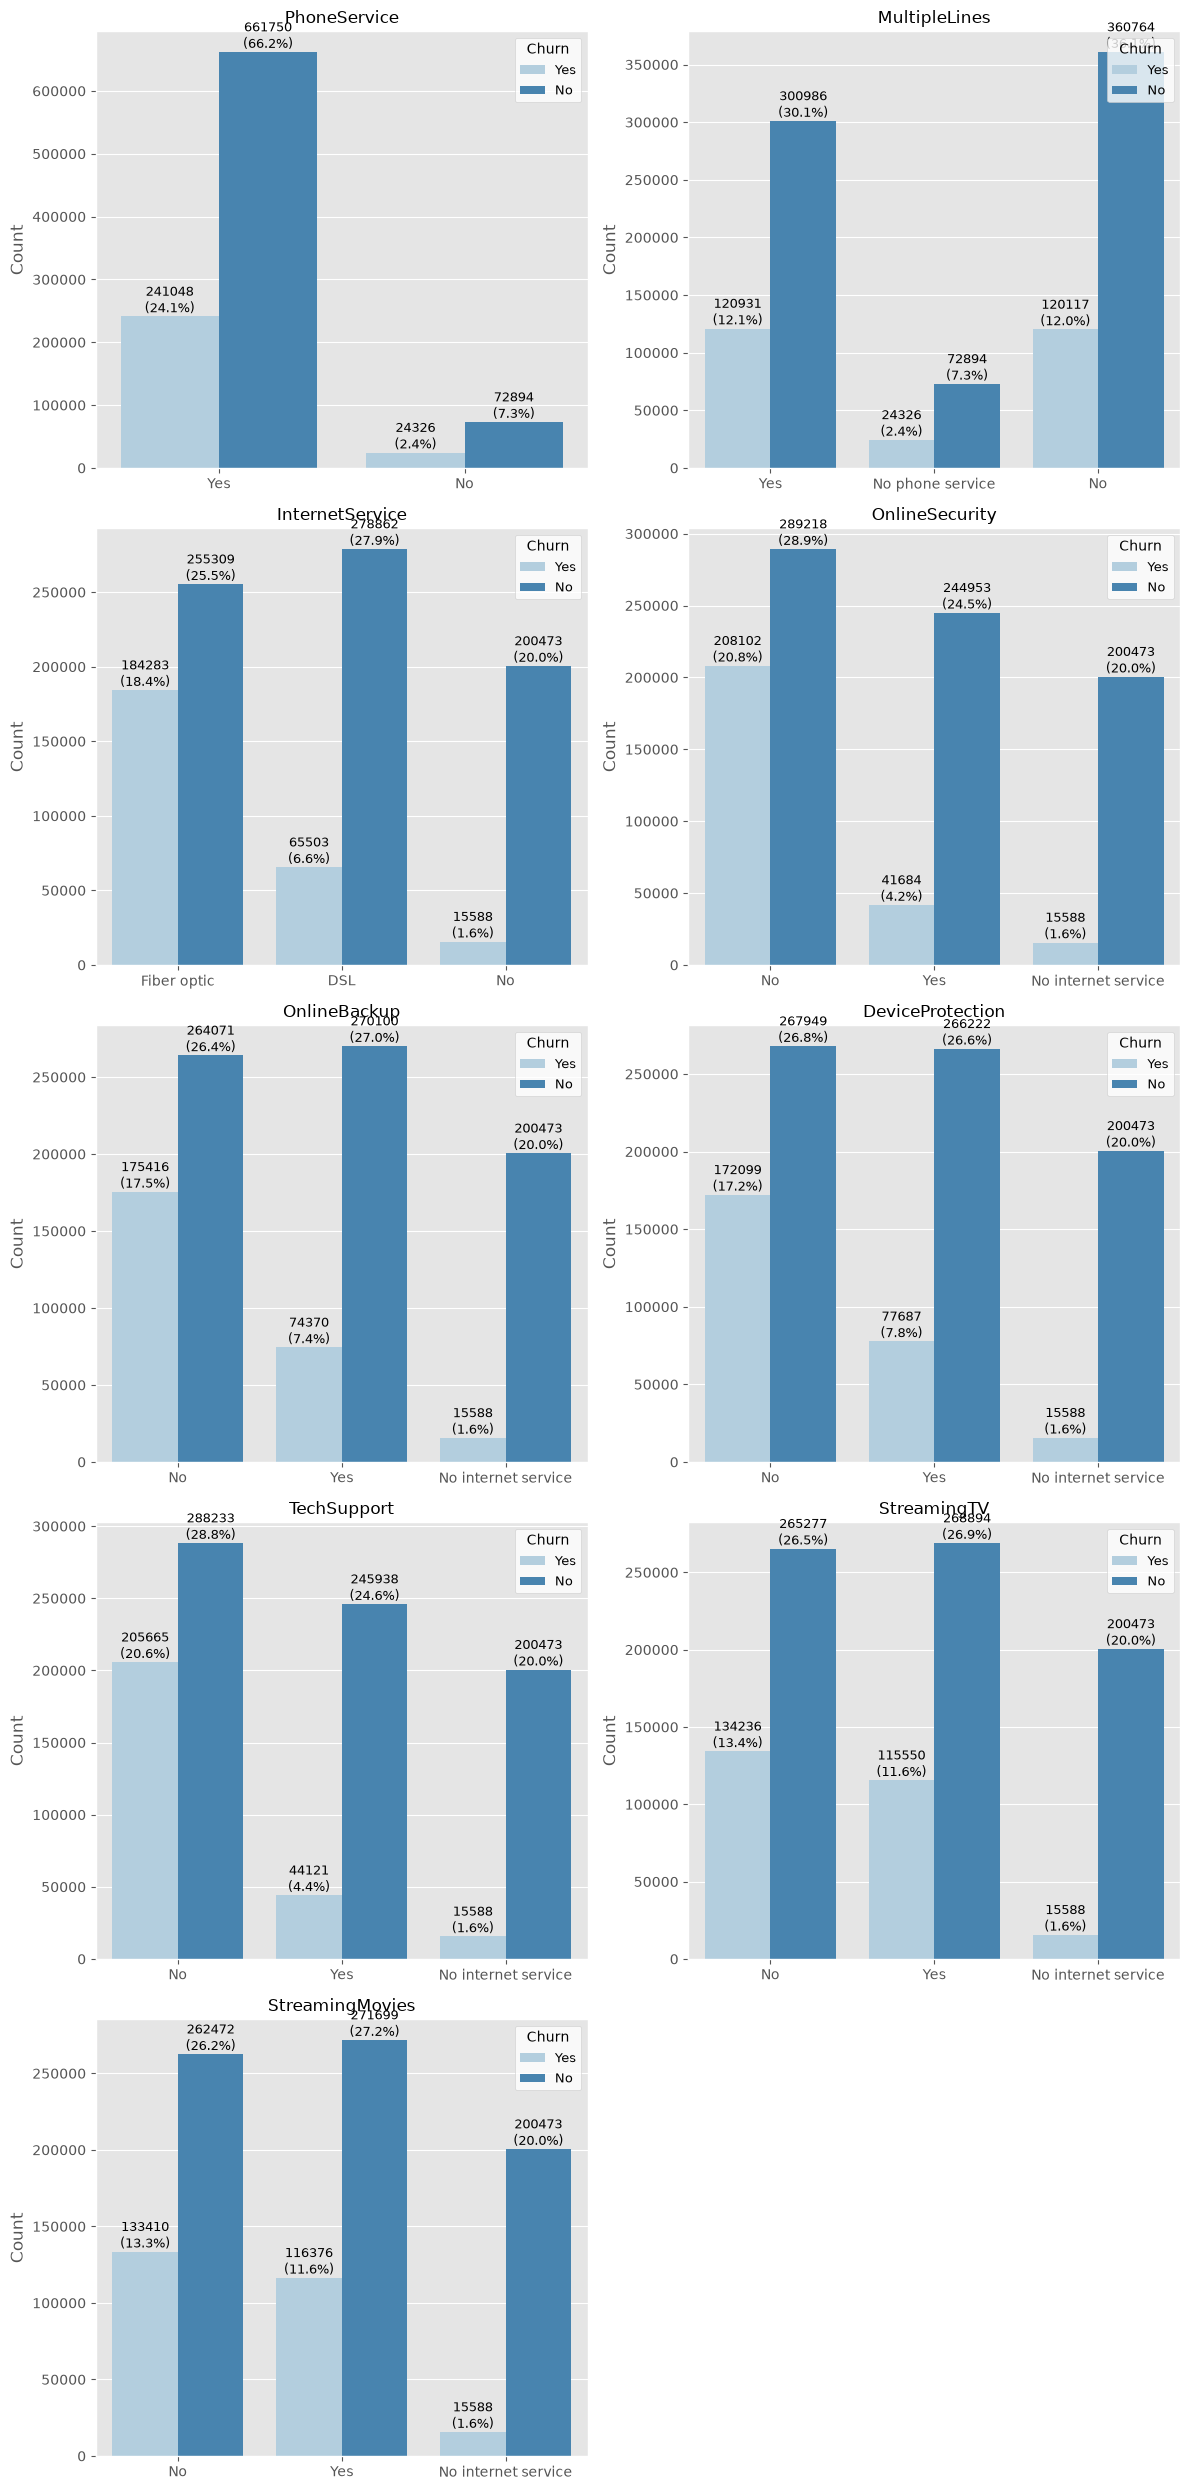

In [12]:
#Analysis of Services of Customers
import math
import matplotlib.pyplot as plt
import seaborn as sns

#Make a function to plot categorical data according to target

def plot_categorical_to_target(data, categorical_values, target):
    number_of_columns = 2
    number_of_rows = math.ceil(len(categorical_values) / 2)

    plt.style.use("ggplot")
    fig = plt.figure(figsize=(12, 5 * number_of_rows))

    for index, column in enumerate(categorical_values, 1):
        ax = fig.add_subplot(number_of_rows, number_of_columns, index)

        # Main countplot
        ax = sns.countplot(
            data=data,
            x=column,
            hue=target,
            palette="Blues",
        )

        # Add count and percentage labels
        total = len(data)
        for container in ax.containers:
            labels = [
                f"{int(v.get_height())}\n({v.get_height()/total:.1%})"
                for v in container
            ]
            ax.bar_label(container, labels=labels, fontsize=9, label_type="edge")

        # Titles and axis formatting
        ax.set_title(column, fontsize=12)
        ax.set_xlabel("")
        ax.set_ylabel("Count")
        ax.tick_params(axis='x', rotation=0)

        # Add an embedded legend (inside each subplot)
        # Get handles and labels only once per plot
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles, labels,
            title=target,
            loc='upper right',          # position inside the subplot
            frameon=True,
            facecolor='white',
            framealpha=0.8,
            fontsize=9,
            title_fontsize=10
        )

    plt.tight_layout()
    plt.show()

# Define your categorical features
customer_services = [
    "PhoneService","MultipleLines","InternetService","OnlineSecurity",
    "OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"
]

# Call the function
plot_categorical_to_target(data, customer_services, "Churn")

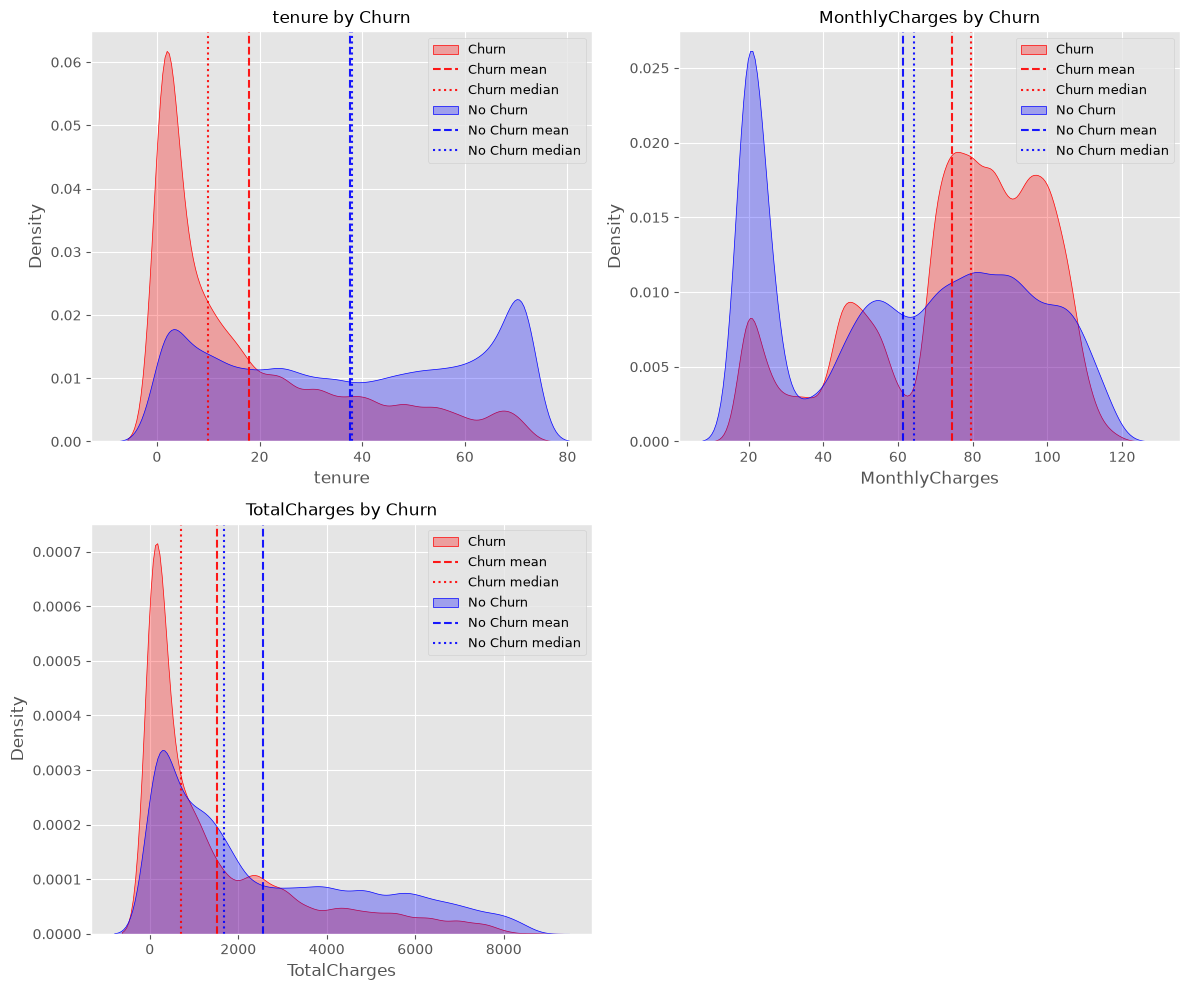

In [13]:
def histogram_plots(
    df,
    numerical_values,
    target,
    save_path="numerical_variables.png",
    sample_size=50_000,
    random_state=42,
):
    if not numerical_values:
        raise ValueError("numerical_values must contain at least one column")
    if sample_size < 1:
        raise ValueError("sample_size must be greater than zero")

    columns = [target, *numerical_values]
    missing_columns = [column for column in columns if column not in df.columns]
    if missing_columns:
        raise KeyError(f"Columns not found in DataFrame: {missing_columns}")

    number_of_columns = 2
    number_of_rows = (len(numerical_values) + number_of_columns - 1) // number_of_columns
    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(12, 5 * number_of_rows),
        squeeze=False,
    )
    axes = axes.ravel()
    target_values = df[target]
    target_groups = pd.unique(target_values.dropna())
    palette = sns.color_palette("deep", n_colors=max(1, len(target_groups)))
    groups = []
    for index, value in enumerate(target_groups):
        normalized = str(value).strip().lower()
        if normalized in {"yes", "1", "true"}:
            color, label = "red", "Churn"
        elif normalized in {"no", "0", "false"}:
            color, label = "blue", "No Churn"
        else:
            color, label = palette[index], str(value)
        groups.append((value, color, label))

    for ax, column in zip(axes, numerical_values):
        values = pd.to_numeric(df[column], errors="coerce")

        for group, color, label in groups:
            group_values = values[target_values.eq(group)].dropna()
            if group_values.empty:
                continue

            kde_values = group_values
            if len(kde_values) > sample_size:
                kde_values = kde_values.sample(
                    n=sample_size,
                    random_state=random_state,
                )

            if kde_values.nunique() > 1:
                sns.kdeplot(
                    x=kde_values,
                    fill=True,
                    alpha=0.3,
                    ax=ax,
                    color=color,
                    label=label,
                    common_norm=False,
                )

            ax.axvline(
                group_values.mean(),
                color=color,
                linestyle="--",
                alpha=0.9,
                label=f"{label} mean",
            )
            ax.axvline(
                group_values.median(),
                color=color,
                linestyle=":",
                alpha=0.9,
                label=f"{label} median",
            )

        ax.set_title(f"{column} by {target}", fontsize=12)
        ax.set_xlabel(column)
        ax.set_ylabel("Density")
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles, labels, loc="upper right", fontsize=9)

    for ax in axes[len(numerical_values):]:
        fig.delaxes(ax)

    fig.tight_layout()
    fig.savefig(save_path, dpi=300)
    plt.show()


# Example usage
customer_account_num = ["tenure", "MonthlyCharges", "TotalCharges"]
histogram_plots(data, customer_account_num, "Churn")

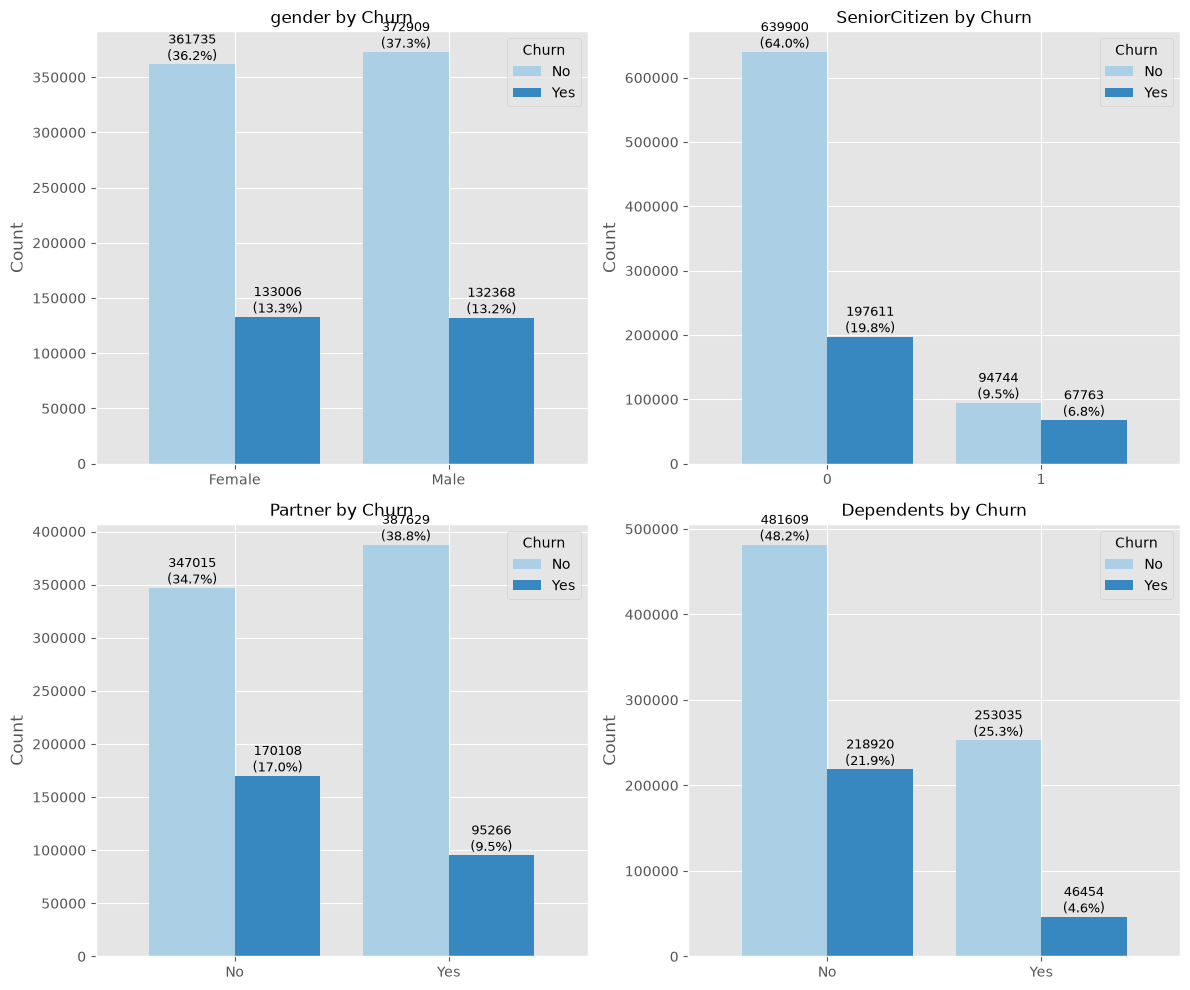

In [14]:
# Analysis of Customer's Demographic Info

def analyze_demographic_churn(df, demographic_values, target):
    if not demographic_values:
        raise ValueError("demographic_values must contain at least one column")
    if df.empty:
        raise ValueError("df must contain at least one row")

    number_of_columns = 2
    number_of_rows = (len(demographic_values) + number_of_columns - 1) // number_of_columns
    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(12, 5 * number_of_rows),
        squeeze=False,
    )
    axes = axes.ravel()
    total = len(df)

    for ax, column in zip(axes, demographic_values):
        counts = pd.crosstab(df[column], df[target])
        colors = sns.color_palette("Blues", n_colors=max(1, len(counts.columns)))
        counts.plot(kind="bar", ax=ax, color=colors, width=0.8)

        for container in ax.containers:
            labels = [
                f"{int(bar.get_height())}\n({bar.get_height() / total:.1%})"
                for bar in container
            ]
            ax.bar_label(container, labels=labels, fontsize=9)

        ax.set_title(f"{column} by {target}", fontsize=12)
        ax.set_xlabel("")
        ax.set_ylabel("Count")
        ax.tick_params(axis="x", rotation=0)
        ax.legend(title=target)

    for ax in axes[len(demographic_values):]:
        fig.delaxes(ax)

    fig.tight_layout()
    plt.show()

# Example usage
demographic_columns = ["gender", "SeniorCitizen", "Partner", "Dependents"]
analyze_demographic_churn(data, demographic_columns, target="Churn")

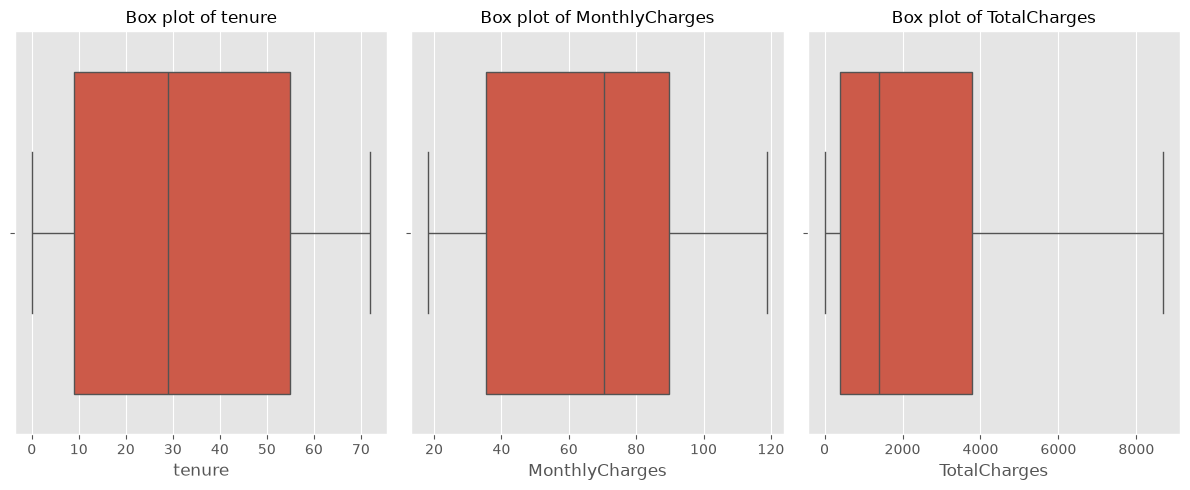

In [15]:
#Outlier Checking with Boxplot for Numerical Variables
#Define a function to create box plots for outlier checking
def outlier_check_boxplot(df, numerical_values):
    if not numerical_values:
        raise ValueError("numerical_values must contain at least one column")
    if df.empty:
        raise ValueError("df must contain at least one row")

    number_of_columns = 3
    number_of_rows = (len(numerical_values) + number_of_columns - 1) // number_of_columns
    fig, axes = plt.subplots(
        number_of_rows,
        number_of_columns,
        figsize=(12, 5 * number_of_rows),
        squeeze=False,
    )

    for ax, column in zip(axes.ravel(), numerical_values):
        sns.boxplot(x=df[column], ax=ax)
        ax.set_title(f"Box plot of {column}", fontsize=12)
        ax.set_xlabel(column)

    for ax in axes.ravel()[len(numerical_values):]:
        fig.delaxes(ax)

    fig.tight_layout()
    plt.show()

# Call the function to check for outliers
numerical_values = ["tenure", "MonthlyCharges", "TotalCharges"]
outlier_check_boxplot(data, numerical_values)

,feature,method,association
14,Contract,Cramer's V,0.410190
4,tenure,Pearson r,-0.352163
8,OnlineSecurity,Cramer's V,0.349724
11,TechSupport,Cramer's V,0.343890
7,InternetService,Cramer's V,0.323610
16,PaymentMethod,Cramer's V,0.304007
9,OnlineBackup,Cramer's V,0.293329
10,DeviceProtection,Cramer's V,0.282497
13,StreamingMovies,Cramer's V,0.232736
12,StreamingTV,Cramer's V,0.232472


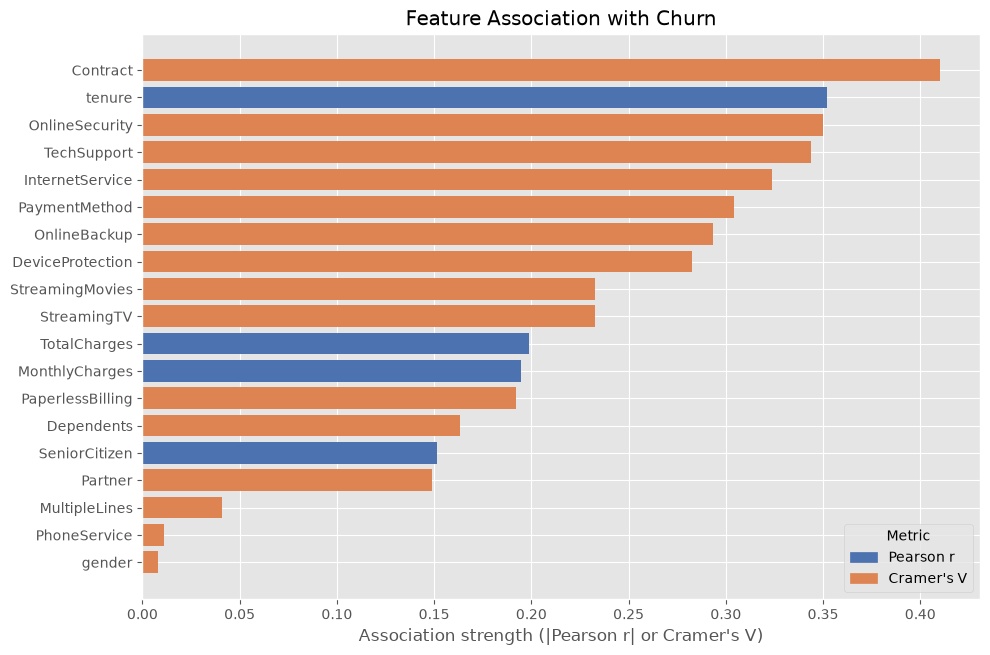

In [16]:
# Correlation and association with Churn
from scipy.stats import chi2_contingency
from matplotlib.patches import Patch

target = data["Churn"]
if pd.api.types.is_numeric_dtype(target):
    churn = pd.to_numeric(target, errors="coerce")
else:
    churn = target.astype("string").str.strip().str.lower().map(
        {"yes": 1, "no": 0, "1": 1, "0": 0}
    )

if churn.isna().any() or not churn.isin([0, 1]).all():
    raise ValueError("Churn must contain only non-null Yes/No or 0/1 values")

predictors = data.drop(columns=["Churn", "CustomerID"], errors="ignore")
records = []
for feature in predictors.columns:
    values = predictors[feature]
    if pd.api.types.is_numeric_dtype(values):
        score = values.corr(churn)
        method = "Pearson r"
        strength = abs(score) if pd.notna(score) else np.nan
    else:
        contingency = pd.crosstab(values, churn)
        if min(contingency.shape) < 2:
            score = np.nan
        else:
            chi2 = chi2_contingency(contingency, correction=False)[0]
            n = contingency.to_numpy().sum()
            score = np.sqrt(chi2 / (n * min(contingency.shape[0] - 1, contingency.shape[1] - 1)))
        method = "Cramer's V"
        strength = score

    records.append({"feature": feature, "method": method, "association": score, "strength": strength})

association_table = pd.DataFrame(records).sort_values(
    "strength",
    ascending=False,
    na_position="last",
)
display(association_table[["feature", "method", "association"]])

plot_data = association_table.dropna(subset=["strength"]).sort_values("strength")
method_colors = {"Pearson r": "#4C72B0", "Cramer's V": "#DD8452"}
fig, ax = plt.subplots(figsize=(10, max(6, 0.35 * len(plot_data))))
ax.barh(
    plot_data["feature"],
    plot_data["strength"],
    color=plot_data["method"].map(method_colors),
)
ax.set_title("Feature Association with Churn")
ax.set_xlabel("Association strength (|Pearson r| or Cramer's V)")
ax.legend(
    handles=[Patch(color=color, label=method) for method, color in method_colors.items()],
    title="Metric",
)
fig.tight_layout()
fig.savefig("correlation.png", dpi=300)
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)
#In train_test_split, the stratify parameter ensures that the proportions of class labels in the training and testing sets are approximately the same as the proportions in the original dataset.

In [18]:
y_train = y_train.map({'Yes': 1, 'No': 0})
y_test = y_test.map({'Yes': 1, 'No': 0})
y = y.map({'Yes': 1, 'No': 0})


In [19]:
print(f"Original data churn rate: {y.mean():.2f}")
print(f"Training data churn rate: {y_train.mean():.2f}")
print(f"Testing data churn rate: {y_test.mean():.2f}")

Original data churn rate: 0.27
Training data churn rate: 0.27
Testing data churn rate: 0.27


In [20]:
from sklearn.compose import ColumnTransformer
# Numeric Preprocessing Batch

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
# Categorical Preprocessing Batch

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
# Combine both batches with ColumnTransformer

preprocessor = ColumnTransformer(
    transformers = [
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)

    ],
    remainder = 'drop'
)

# Create the final, full-stack pipeline
clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight = 'balanced',
        random_state = 42,

    ))
])


In [21]:
data["Churn"] = (
    data["Churn"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

X = data.drop(columns=["Churn", "CustomerID"])
y = data["Churn"]

# Keep only valid target rows
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Missing targets:", pd.isna(y_train).sum())
clf_pipeline.fit(X_train, y_train)

Missing targets: 0


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [22]:
y_predict = clf_pipeline.predict(X_test)
print(y_predict)

[1 1 0 ... 0 1 0]


In [23]:
y_proba = clf_pipeline.predict_proba(X_test)[:, 1]
print(y_proba)


[0.64614553 0.61295455 0.17655634 ... 0.28895096 0.83434017 0.10678102]


In [24]:
print(recall_score(y_test, y_predict))


0.8081959491285916


In [25]:
print(confusion_matrix(y_test, y_predict))

[[106683  40246]
 [ 10180  42895]]


In [26]:
print(precision_score(y_test, y_predict))

0.5159307682130357


In [27]:
print(accuracy_score(y_test, y_predict))

0.74787504249915


In [28]:
print(f1_score(y_test, y_predict))

0.6298085393786339


In [29]:
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81    146929
           1       0.52      0.81      0.63     53075

    accuracy                           0.75    200004
   macro avg       0.71      0.77      0.72    200004
weighted avg       0.81      0.75      0.76    200004



In [30]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(roc_auc)

0.8477524650725863


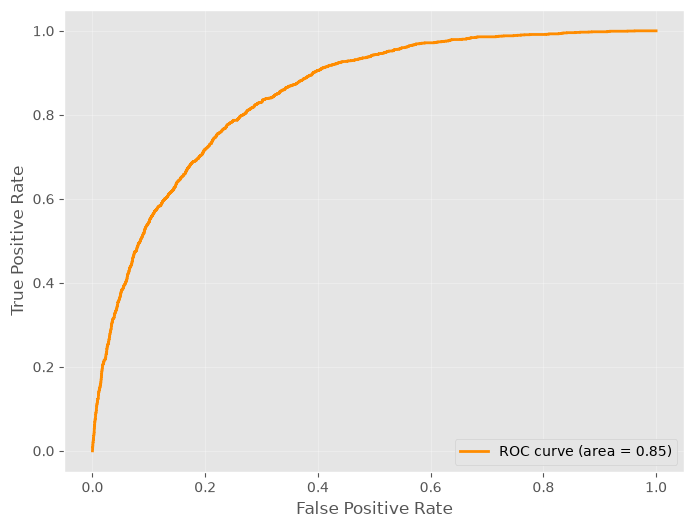

In [31]:
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [32]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators = 200,
        class_weight = 'balanced',
        random_state = 42,

    ))
])

In [33]:
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

In [34]:
# Ensure the prediction exists, even if the previous cell was not executed
y_pred_rf = rf_model.predict(X_test)

y_test_array = y_test.to_numpy(dtype=np.int64)
y_pred_rf_array = np.asarray(y_pred_rf, dtype=np.int64)

report: str = classification_report(
    y_test_array,
    y_pred_rf_array,
    output_dict=False
)

print(report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    146929
           1       0.99      1.00      0.99     53075

    accuracy                           1.00    200004
   macro avg       0.99      1.00      1.00    200004
weighted avg       1.00      1.00      1.00    200004



In [35]:
print(confusion_matrix(y_test, y_pred_rf))

[[146401    528]
 [    27  53048]]


In [36]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print(roc_auc_rf)

0.9999823935649054


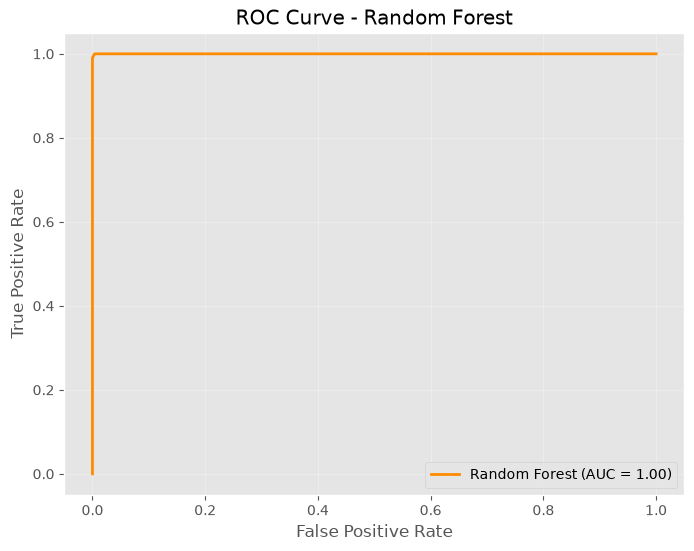

In [37]:
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2, label=f"Random Forest (AUC = {roc_auc_rf:.2f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [38]:
from sklearn.model_selection import cross_val_score

cv_auc = cross_val_score(
    clf_pipeline, X_train, y_train,
    scoring='roc_auc',
    cv=5
)
print("Logistic Regression CV AUC:", cv_auc.mean())

Logistic Regression CV AUC: 0.8491571406789274


In [39]:
from sklearn.metrics import roc_auc_score

rf_model.fit(X_train, y_train)
y_score_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest test AUC:", roc_auc_score(y_test, y_score_rf))

Random Forest test AUC: 0.9999823935649054


In [40]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 10],
    'model__min_samples_leaf': [1, 5]
}

In [41]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import roc_auc_score

# Tune on a representative subset rather than all training rows
n_search = min(30_000, len(X_train))
X_search, _, y_search, _ = train_test_split(
    X_train,
    y_train,
    train_size=n_search,
    random_state=42,
    stratify=y_train,
)

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=6,
    scoring="roc_auc",
    cv=2,
    refit=False,
    n_jobs=-1,
    pre_dispatch="n_jobs",
    random_state=42,
    verbose=1,
)

rf_search.fit(X_search, y_search)

# Apply the selected settings, then train once using all training data
rf_model.set_params(**rf_search.best_params_)
rf_model.fit(X_train, y_train)

print("Best parameters:", rf_search.best_params_)
print("Test AUC:", roc_auc_score(
    y_test, rf_model.predict_proba(X_test)[:, 1]
))

Fitting 2 folds for each of 6 candidates, totalling 12 fits
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Test AUC: 0.9999823935649054


In [42]:
print("Best RF Params:", rf_search.best_params_)
print("Best RF sampled CV AUC:", rf_search.best_score_)

Best RF Params: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Best RF sampled CV AUC: 0.9920465975304618


In [43]:
# rf_model must have been fitted in the previous search cell
best_rf = rf_model

y_pred_rf = best_rf.predict(X_test)
y_pred_proba_rf = best_rf.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
print("ROC AUC:", roc_auc_rf)
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))


ROC AUC: 0.9999823935649054
Accuracy: 0.9972250554988901
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    146929
           1       0.99      1.00      0.99     53075

    accuracy                           1.00    200004
   macro avg       0.99      1.00      1.00    200004
weighted avg       1.00      1.00      1.00    200004



In [44]:

feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()
importances = best_rf.named_steps['model'].feature_importances_

feat_imp = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

feat_imp.head(15)

,feature,importance
1,num__TotalCharges,0.151090
2,num__tenure,0.137768
0,num__MonthlyCharges,0.130267
37,cat__Contract_Month-to-month,0.066949
39,cat__Contract_Two year,0.035543
19,cat__OnlineSecurity_No,0.033183
28,cat__TechSupport_No,0.029880
44,cat__PaymentMethod_Electronic check,0.026295
17,cat__InternetService_Fiber optic,0.025002
22,cat__OnlineBackup_No,0.017845


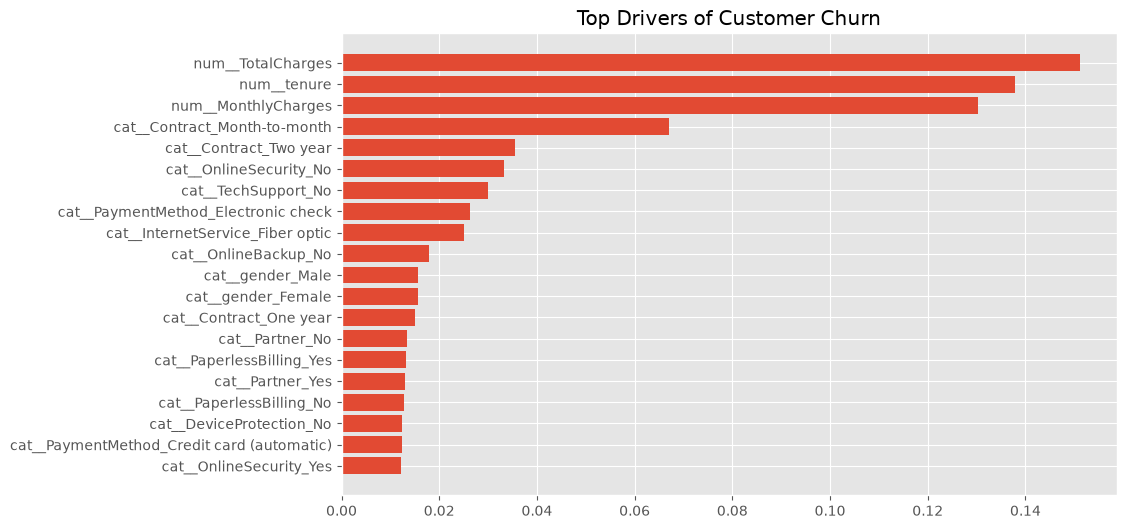

In [45]:

top_features = feat_imp.head(20)
plt.figure(figsize=(10, 6))
plt.barh(top_features['feature'], top_features['importance'])
plt.gca().invert_yaxis()
plt.title("Top Drivers of Customer Churn")
plt.show()

In [46]:

thresholds = np.arange(0.1, 0.9, 0.05)

results = []

for t in thresholds:
    y_pred_custom = (y_pred_proba_rf >= t).astype(int)

    precision = precision_score(y_test, y_pred_custom)
    recall = recall_score(y_test, y_pred_custom)
    f1 = f1_score(y_test, y_pred_custom)

    results.append((t, precision, recall, f1))

results_df = pd.DataFrame(results, columns=["threshold", "precision", "recall", "f1"])
results_df

,threshold,precision,recall,f1
0,0.10,0.988582,1.000000,0.994258
1,0.15,0.988582,1.000000,0.994258
2,0.20,0.988582,1.000000,0.994258
3,0.25,0.988582,1.000000,0.994258
4,0.30,0.988582,1.000000,0.994258
5,0.35,0.988582,1.000000,0.994258
6,0.40,0.988582,1.000000,0.994258
7,0.45,0.988582,1.000000,0.994258
8,0.50,0.990145,0.999491,0.994796
9,0.55,0.991323,0.998832,0.995063


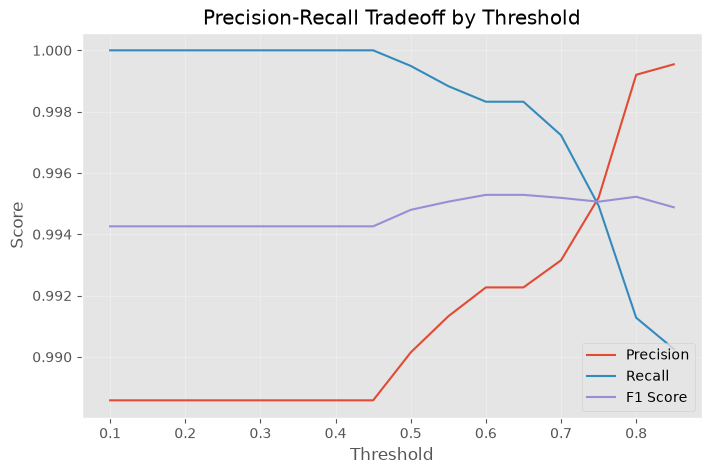

In [47]:
plt.figure(figsize=(8,5))
plt.plot(results_df["threshold"], results_df["precision"], label="Precision")
plt.plot(results_df["threshold"], results_df["recall"], label="Recall")
plt.plot(results_df["threshold"], results_df["f1"], label="F1 Score")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision-Recall Tradeoff by Threshold")
plt.grid(alpha=0.3)
plt.show()

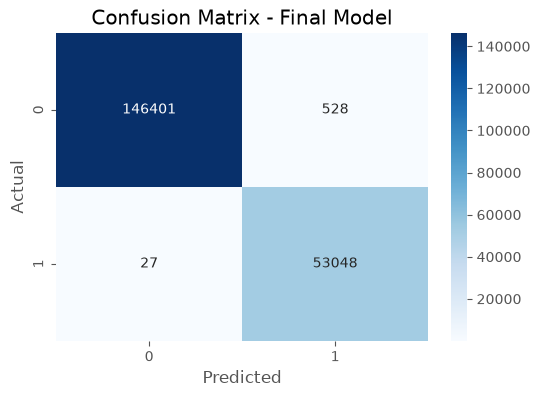

In [48]:
y_pred_final = best_rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Final Model")
plt.show()

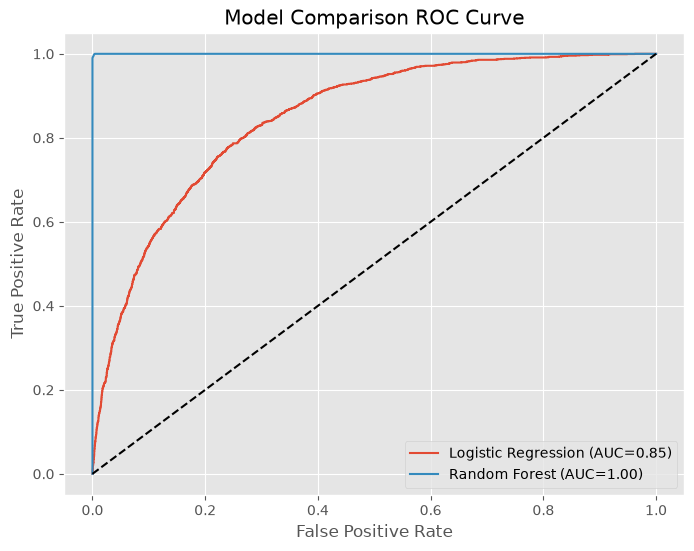

In [49]:
plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={roc_auc:.2f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC={roc_auc_rf:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Model Comparison ROC Curve")
plt.legend()
plt.show()

In [50]:
churn_prob = y_pred_proba_rf

risk_df = pd.DataFrame({
    "churn_probability": churn_prob
})

risk_df["risk_level"] = pd.cut(
    risk_df["churn_probability"],
    bins=[0,0.3,0.6,1],
    labels=["Low Risk","Medium Risk","High Risk"]
)

risk_df["risk_level"].value_counts()

risk_level
High Risk      53399
Medium Risk      289
Low Risk           0
Name: count, dtype: int64

In [51]:
import joblib

joblib.dump(clf_pipeline, "logistic_model.pkl")
joblib.dump(best_rf, "rf_model.pkl")

['rf_model.pkl']

In [52]:
import sklearn
print(sklearn.__version__)

1.9.1


In [53]:
import shap
X_train_transformed = best_rf.named_steps['preprocessor'].transform(X_train)

In [54]:
feature_names = best_rf.named_steps['preprocessor'].get_feature_names_out()

In [55]:
rf_classifier = best_rf.named_steps["model"]

# Explain a reproducible sample instead of the entire training set
X_explain = X_train.sample(
    n=min(1_000, len(X_train)),
    random_state=42,
)
X_explain_transformed = best_rf.named_steps["preprocessor"].transform(X_explain)

explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer.shap_values(X_explain_transformed)

In [56]:
print(type(shap_values))
print(len(shap_values))
print(shap_values[1].shape)
print(X_train_transformed.shape)

<class 'numpy.ndarray'>
1000
(46, 2)
(800014, 46)


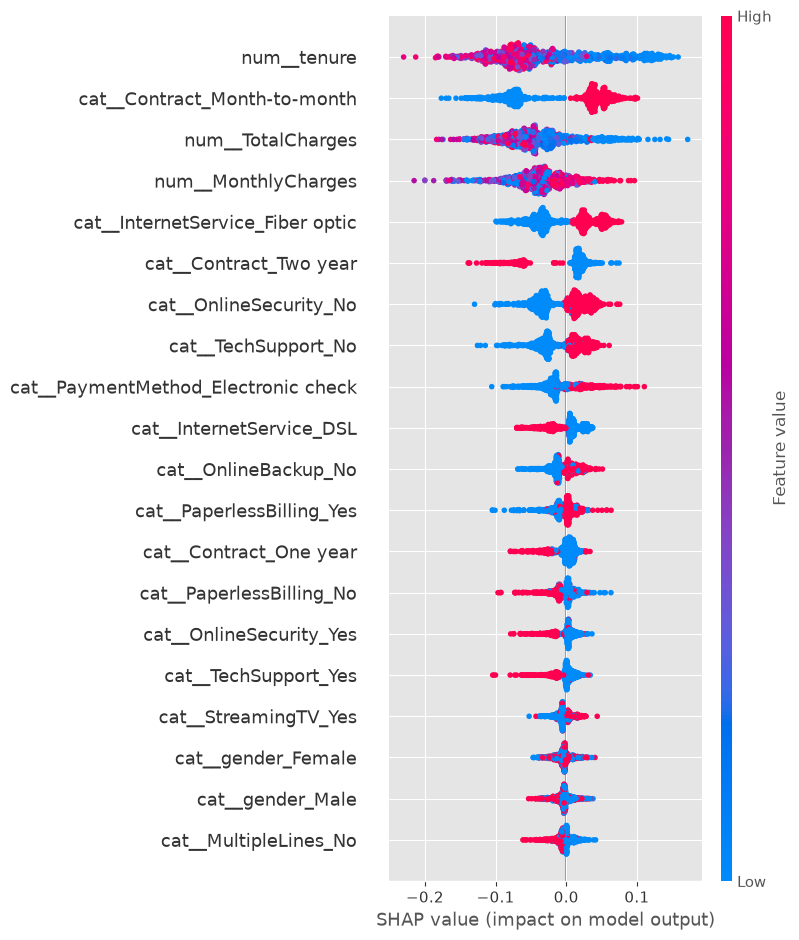

In [57]:
import numpy as np

X = np.asarray(X_explain_transformed)

if hasattr(shap_values, "values"):
    shap_array = shap_values.values
elif isinstance(shap_values, list):
    shap_array = np.asarray(shap_values[1])
else:
    shap_array = np.asarray(shap_values)

# Select the positive/churn class
if shap_array.ndim == 3:
    if shap_array.shape[0] == X.shape[0]:
        values = shap_array[:, :, 1]
    elif shap_array.shape[1] == X.shape[0]:
        values = shap_array[:, :, 1].T
    else:
        raise ValueError(
            f"Cannot align SHAP shape {shap_array.shape} with features {X.shape}"
        )
else:
    values = shap_array

assert values.shape == X.shape, (
    f"SHAP shape {values.shape} != feature shape {X.shape}"
)

shap.summary_plot(
    values,
    X,
    feature_names=feature_names
)

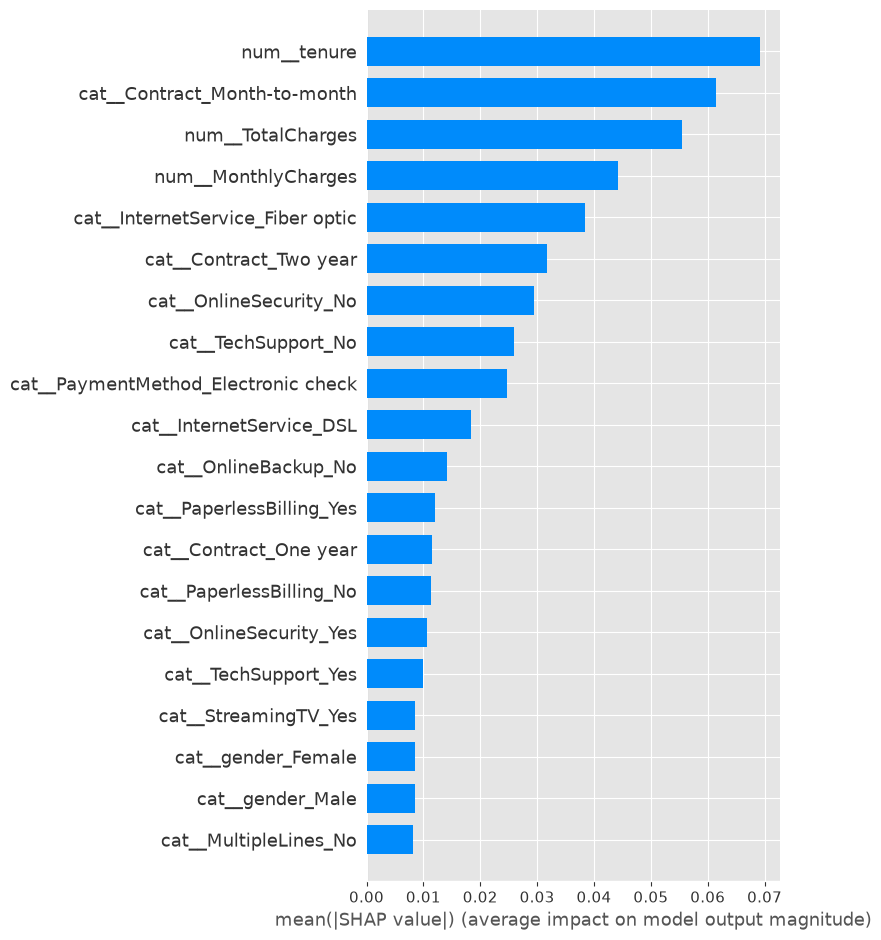

In [58]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_explain_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

In [59]:
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos

In [60]:
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

In [61]:
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [62]:
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("ROC AUC:", roc_auc_score(y_test, y_proba_xgb))

              precision    recall  f1-score   support

           0       0.93      0.76      0.84    146929
           1       0.56      0.85      0.68     53075

    accuracy                           0.79    200004
   macro avg       0.75      0.81      0.76    200004
weighted avg       0.84      0.79      0.80    200004

ROC AUC: 0.8905491935478002


In [63]:
performance_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "ROC AUC": [0.86, 0.85, round(roc_auc_score(y_test, y_proba_xgb), 2)],
    "F1 Score": [0.64, 0.65, round(f1_score(y_test, y_pred_xgb), 2)],
    "Precision": [0.52, 0.56, round(precision_score(y_test, y_pred_xgb), 2)],
    "Recall": [0.84, 0.78, round(recall_score(y_test, y_pred_xgb), 2)]
})
performance_df

,Model,ROC AUC,F1 Score,Precision,Recall
0,Logistic Regression,0.86,0.64,0.52,0.84
1,Random Forest,0.85,0.65,0.56,0.78
2,XGBoost,0.89,0.68,0.56,0.85


In [64]:
joblib.dump(xgb_model, "xgb_model.pkl")


['xgb_model.pkl']